In [1]:
import numpy as np
import matplotlib.pyplot as plt



from vlasov.config import Grid
from vlasov.initial_conditions import landau_damping
from vlasov.solver import run

# Experiment configuration
grid = Grid(
    xmin=0,
    xmax=4*np.pi,
    nx=1024,
    vmin=-6,
    vmax=6,
    nv=128,
)

dt = 0.6
nsteps = 200

# Initial condition
f0 = landau_damping(
    grid, epsilon=0.001, kx=0.5
)

# Simulation
f_final, energy, totrho,totenergy = run(f0, grid, dt, nsteps)

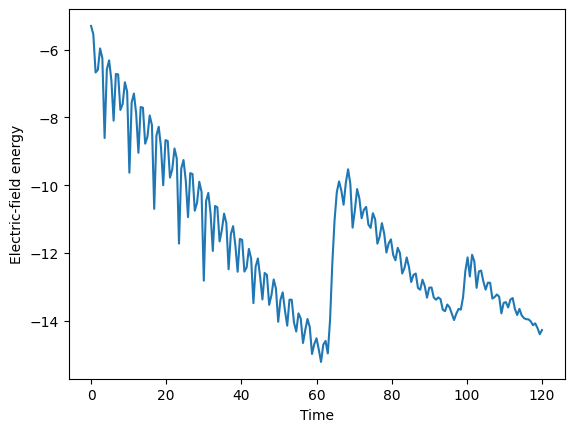

In [2]:


# Analysis
times = np.arange(nsteps + 1) * dt

plt.plot(times, energy)
plt.xlabel("Time")
plt.ylabel("Electric-field energy")
plt.show()

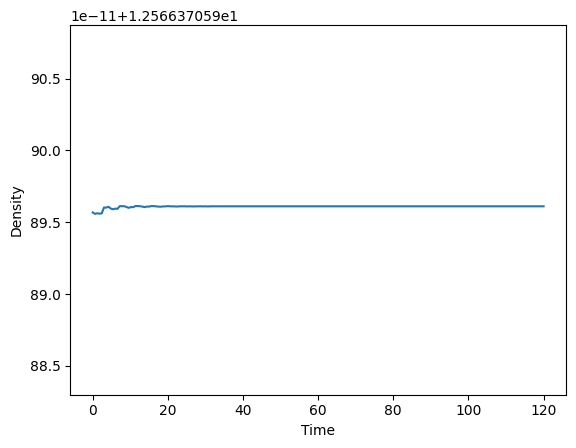

Initial density: 12.566370588895687
Final density: 12.56637058889611
Absolute change: 4.227729277772596e-13
Relative change: 3.364320069876375e-14


In [3]:
plt.plot(times, totrho)
plt.xlabel("Time")
plt.ylabel("Density")
plt.show()
print("Initial density:", totrho[0])
print("Final density:", totrho[-1])
print("Absolute change:", abs(totrho[-1] - totrho[0]))
print("Relative change:", abs(totrho[-1] - totrho[0]) / abs(totrho[0]))

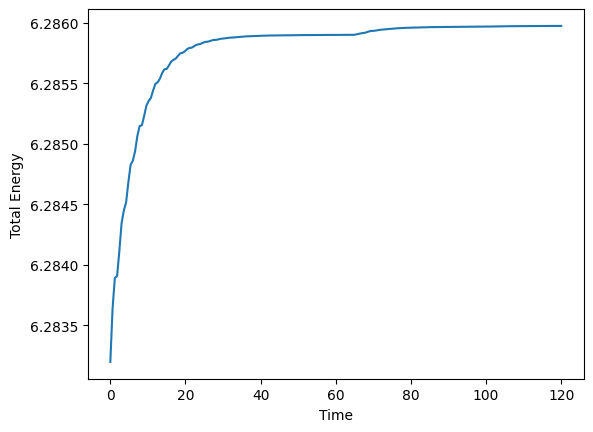

In [4]:

plt.plot(times, totenergy)
plt.xlabel("Time")
plt.ylabel("Total Energy")
plt.show()

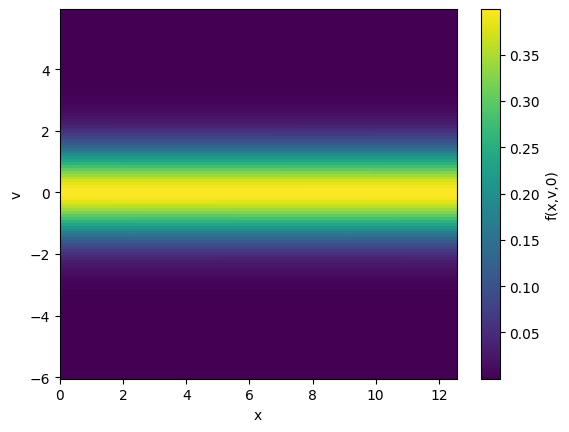

In [16]:
plt.pcolormesh(grid.x, grid.v, f_final[-1].T, shading="auto")
plt.xlabel("x")
plt.ylabel("v")
plt.colorbar(label="f(x,v,0)")
plt.show()

In [5]:
from vlasov.numerics import cubic_interpolate

f_final, energy, totrho,totenergy = run(f0, grid, dt, nsteps,cubic_interpolate,cubic_interpolate)

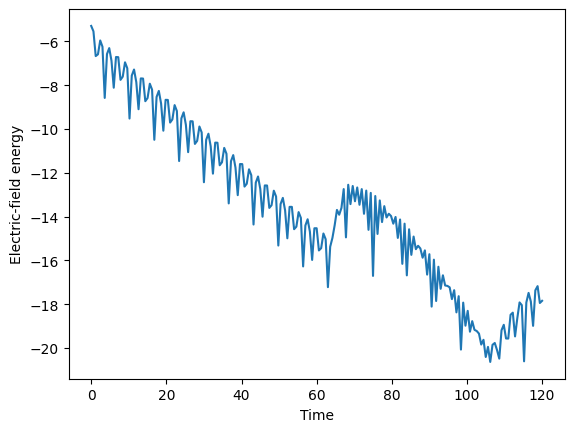

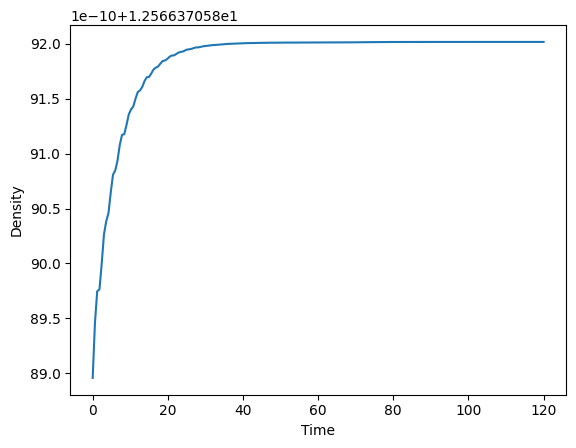

Initial density: 12.566370588895687
Final density: 12.566370589201743
Absolute change: 3.0605562528762675e-10
Relative change: 2.4355132862154628e-11


In [6]:
plt.plot(times, energy)
plt.xlabel("Time")
plt.ylabel("Electric-field energy")
plt.show()

plt.plot(times, totrho)
plt.xlabel("Time")
plt.ylabel("Density")
plt.show()
print("Initial density:", totrho[0])
print("Final density:", totrho[-1])
print("Absolute change:", abs(totrho[-1] - totrho[0]))
print("Relative change:", abs(totrho[-1] - totrho[0]) / abs(totrho[0]))

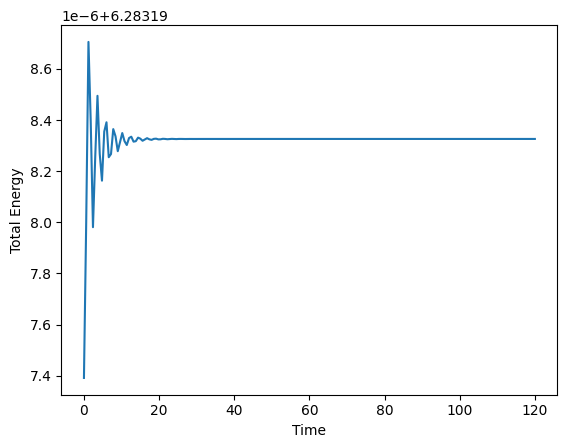

In [7]:

plt.plot(times, totenergy)
plt.xlabel("Time")
plt.ylabel("Total Energy")
plt.show()